# 03 · The slice simulator: normal behaviour, coupling and memory

**Goal.** Before injecting faults, understand what *normal* KPIs look like in a simulated cell with three slices sharing one resource pool. Three properties decide how detectors must be built:

1. **Coupling:** are the KPIs of different slices correlated? This is the $\Sigma$ of notebook 02. Is it there at all, and does it survive once each stream's own memory is removed?
2. **Memory:** how autocorrelated is each KPI over time? Notebook 01 showed that memory inflates false alarms.
3. **Shape:** how far from Gaussian are the KPIs?

The simulator lives in `src/slicead/sim/` (tests: `tests/test_sim.py`); its scenario is `configs/sim_default.yaml`.

**Run it** from the project root (about 2–3 minutes). Figures go to `results/03_slice_simulator/` and `report/figures/`.

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/03_slice_simulator.ipynb
```

**Sections:** 1 Setup · 2 The model · 3 Checks · 4 Normal behaviour · 5 Coupling across slices · 6 Memory · 7 Shape · 8 Higher load · 9 Summary

In [1]:
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from slicead.sim import load_config, simulate, KPI_NAMES

SEED = 20261022
OUT = Path("../results/03_slice_simulator")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)
(REPORT / "figures").mkdir(parents=True, exist_ok=True)
(REPORT / "tables").mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"03_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    # tabular only; caption and label live in report/main.tex
    (REPORT / "tables" / f"03_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"03_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SLICE_COLORS = [BLUE, ORANGE, AQUA]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 7, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
KPI_LABEL = {"throughput_mbps": "throughput (Mbit/s)", "latency_ms": "latency (ms)",
             "jitter_ms": "jitter (ms)", "loss_pct": "loss (%)"}
print(f"offered load: {cfg.offered_load():.2f} of nominal capacity")

offered load: 0.56 of nominal capacity


## 2. The model

Time runs in **1 ms slots**; KPIs are reported per **100 ms window**. In every slot:

1. **Arrivals.** Each slice's packets arrive and join its first-in-first-out queue. eMBB is an *on-off* source: bursts at 96 Mbit/s alternate with quiet periods at 12 Mbit/s, with exponential durations (mean 200 ms on, 300 ms off). URLLC and mMTC are Poisson. Packets that do not fit in the slice's buffer are dropped.
2. **Sharing.** The slot's capacity is split by **work-conserving weighted water-filling**: every backlogged slice gets capacity in proportion to its weight (eMBB 0.5, URLLC 0.3, mMTC 0.2), and capacity a slice cannot use is passed on to the others. This is generalised processor sharing (GPS), the fluid ideal of weighted fair queueing, applied one slot at a time. It is how slicing gives each slice a guaranteed share while letting it borrow idle capacity.
3. **Radio.** Capacity fluctuates around 100 Mbit/s as an AR(1) process ($\pm$10%, correlation time 0.5 s), standing for radio conditions that affect every slice at once. A small fraction of transmitted packets is lost on the link.

**Latency** is computed exactly for the fluid model: the delay of a bit is the *horizontal distance* between the slice's cumulative-arrival curve and cumulative-departure curve, the same picture as network calculus. Within a slot, a slice's bits leave at its GPS rate. **Jitter** is the standard deviation of delay within a window. **Loss** counts buffer drops and radio losses. Latency here is scheduling delay only; fixed processing and propagation delays would add a constant and do not matter for detection.

Signals link: the per-slice queue is Lindley's recursion again, $Q_n = \max(0, Q_{n-1} + A_n - S_n)$, a nonlinear low-pass filter of the traffic. That is why we expect the KPIs to have memory.

In [2]:
rows = []
for s in cfg.slices:
    t = s.traffic
    if t.model == "onoff":
        traffic = f"on-off, {t.on_rate_pps * s.packet_bits / 1e6:g}/{t.off_rate_pps * s.packet_bits / 1e6:g} Mbit/s, {t.mean_on_ms:g}/{t.mean_off_ms:g} ms"
    else:
        traffic = "Poisson"
    rows.append({"slice": s.name, "weight": s.weight, "guaranteed (Mbit/s)": s.weight * cfg.capacity.mbps,
                 "mean offered (Mbit/s)": t.mean_rate_pps() * s.packet_bits / 1e6, "traffic": traffic,
                 "packet (bytes)": s.packet_bits // 8, "buffer (ms)": s.buffer_ms, "radio loss": s.radio_loss})
params = pd.DataFrame(rows)
tab = params.assign(**{
    "weight": params["weight"].map("{:g}".format),
    "guaranteed (Mbit/s)": params["guaranteed (Mbit/s)"].map("{:g}".format),
    "mean offered (Mbit/s)": params["mean offered (Mbit/s)"].map("{:.1f}".format),
    "radio loss": params["radio loss"].map(lambda v: f"$10^{{{int(np.log10(v))}}}$"),
    "buffer (ms)": params["buffer (ms)"].map("{:g}".format),
})
save_tex_table(tab, "slices", "lrrrlrrr")
params

,slice,weight,guaranteed (Mbit/s),mean offered (Mbit/s),traffic,packet (bytes),buffer (ms),radio loss
0,eMBB,0.5,50.0,45.6,"on-off, 96/12 Mbit/s, 200/300 ms",1500,100.0,0.00100
1,URLLC,0.3,30.0,2.0,Poisson,100,10.0,0.00001
2,mMTC,0.2,20.0,8.0,Poisson,50,50.0,0.00100


## 3. Checks

`tests/test_sim.py` checks the simulator against cases with known answers (run `.venv\Scripts\python -m pytest`):

- water-filling gives weight-proportional shares when every slice is saturated, passes on unused capacity, and is work-conserving;
- a lone slice with Poisson batches and ample capacity has bit-weighted mean delay $L(1+\lambda)/(2C)$ exactly (to within 2%);
- two saturated slices receive 70/30 of capacity when weighted 0.7/0.3;
- throughput equals offered traffic minus losses;
- no bit waits longer than the buffer can hold at the slice's minimum guaranteed rate;
- the same seed reproduces the same output.

## 4. Normal behaviour

Four independent runs of 10 simulated minutes each (6,000 windows per run). All four advance together as numpy arrays, so this costs about as much as one run.

In [3]:
N_RUNS, N_WINDOWS = 4, 6000
res = simulate(cfg, n_windows=N_WINDOWS, n_runs=N_RUNS, seed=SEED)
names = res.slice_names
print("windows with no arrivals (latency undefined):", int(np.isnan(res.kpi("latency_ms")).sum()))

summary = []
for s, name in enumerate(names):
    for k in KPI_NAMES:
        v = res.kpi(k)[..., s].ravel()
        v = v[~np.isnan(v)]
        summary.append(dict(slice=name, kpi=k, mean=v.mean(), sd=v.std(), p50=np.median(v),
                            p99=np.percentile(v, 99), skewness=stats.skew(v)))
summary = pd.DataFrame(summary)
summary.round(3)

windows with no arrivals (latency undefined): 0


,slice,kpi,mean,sd,p50,p99,skewness
0,eMBB,throughput_mbps,45.777,33.754,36.720,99.459,0.274
1,eMBB,latency_ms,8.314,15.371,0.987,64.368,2.367
2,eMBB,jitter_ms,1.858,3.058,0.575,15.403,3.169
3,eMBB,loss_pct,0.768,3.446,0.000,20.167,6.085
4,URLLC,throughput_mbps,2.000,0.126,2.000,2.296,0.068
5,URLLC,latency_ms,0.042,0.007,0.042,0.059,0.518
6,URLLC,jitter_ms,0.021,0.003,0.021,0.031,0.689
7,URLLC,loss_pct,0.001,0.019,0.000,0.000,20.914
8,mMTC,throughput_mbps,7.992,0.180,7.992,8.416,0.009
9,mMTC,latency_ms,0.185,0.027,0.183,0.254,0.520


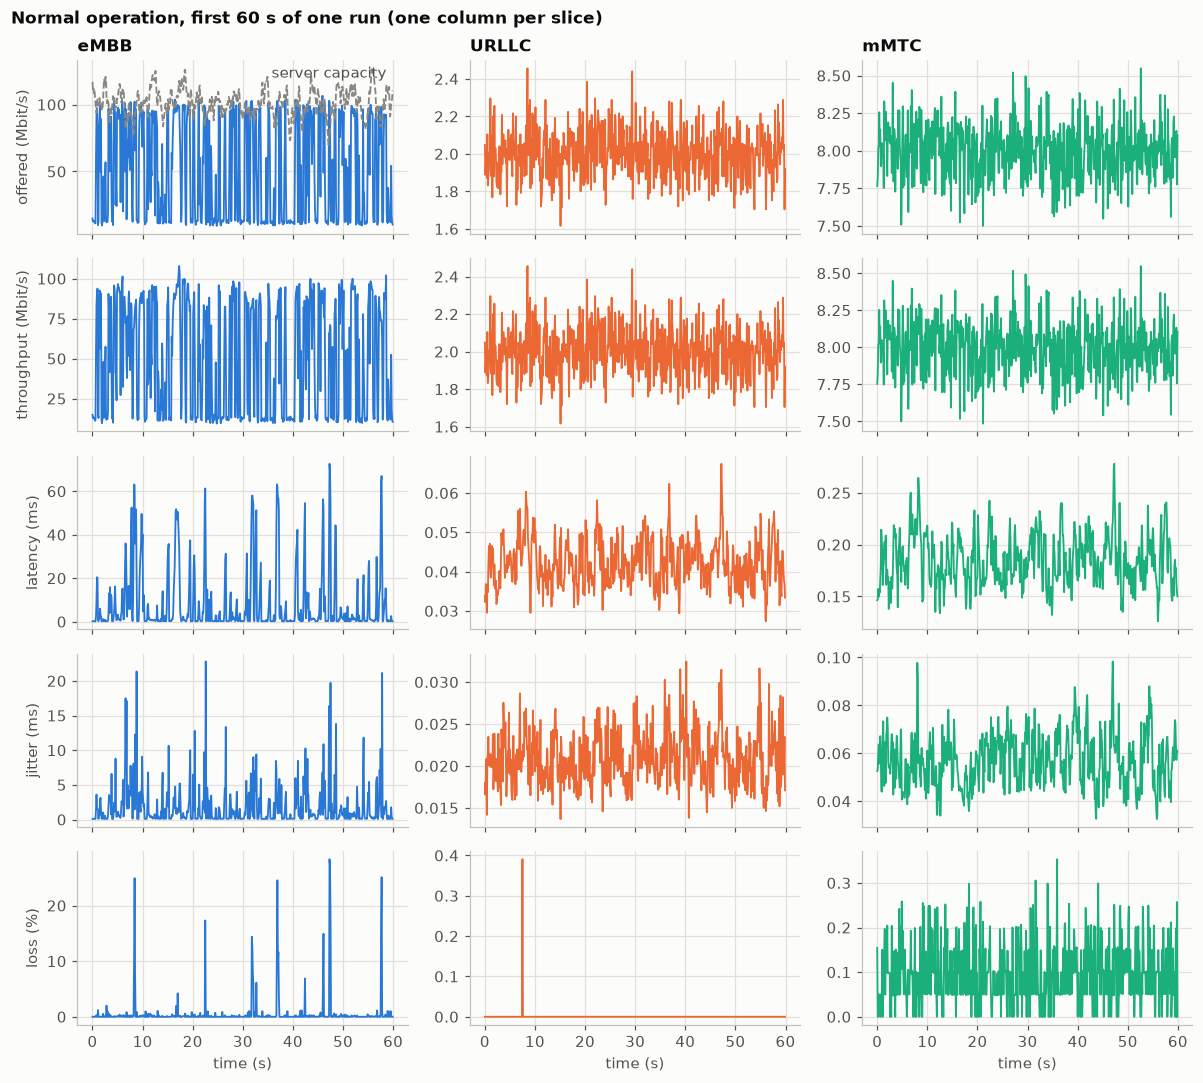

In [4]:
t0, t1 = 0, 600                                    # first 60 s of run 0
tt = res.time_s[t0:t1]
fig, axes = plt.subplots(5, 3, figsize=(11, 10), sharex=True)
for s, name in enumerate(names):
    ax = axes[0, s]
    ax.plot(tt, res.offered_mbps[0, t0:t1, s], color=SLICE_COLORS[s], lw=1.2)
    ax.set_title(name)
    if s == 0:
        ax.plot(tt, res.capacity_mbps[0, t0:t1], color=MUTED, lw=1.2, ls="--")
        ax.annotate("server capacity", (tt[-1], res.capacity_mbps[0, t1 - 1]), xytext=(-4, 6),
                    textcoords="offset points", ha="right", va="bottom", color=INK2)
    for r, k in enumerate(KPI_NAMES, start=1):
        axes[r, s].plot(tt, res.kpi(k)[0, t0:t1, s], color=SLICE_COLORS[s], lw=1.2)
axes[0, 0].set_ylabel("offered (Mbit/s)")
for r, k in enumerate(KPI_NAMES, start=1):
    axes[r, 0].set_ylabel(KPI_LABEL[k])
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
fig.suptitle("Normal operation, first 60 s of one run (one column per slice)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_kpi_traces")
plt.show()

**What it shows**

- **The default scenario behaves as designed.** eMBB alternates between quiet periods (12 Mbit/s) and bursts near 96 Mbit/s. During a burst it borrows the capacity the other slices leave idle, so its queue builds and drains. Its latency is usually about 1 ms, but climbs to tens of ms in long bursts (mean 8.3 ms, 99th percentile 64 ms), with loss spikes when its 100 ms buffer fills.
- **URLLC and mMTC are protected.** Their traffic is far below their guaranteed shares, so they deliver everything they are offered. Their latency stays well under a millisecond (URLLC 42 µs on average), but it visibly rises and falls with eMBB's bursts.
- **Not every KPI is informative.** URLLC loss is almost always exactly zero: a radio loss of $10^{-5}$ means about one lost packet every 400 windows. A detector on it would need a count model, not a Gaussian one.

## 5. Coupling across slices

The coupled detector of notebook 02 uses the correlation $\Sigma$ between slices. We look at it twice:

- **raw:** correlation of the window KPIs themselves;
- **after whitening:** each stream is first passed through its own AR(1) prediction-error filter, $e_n = (x_n - \bar x) - \hat\phi\,(x_{n-1} - \bar x)$, with $\hat\phi$ its lag-1 autocorrelation. This removes most of each stream's memory (section 6). What remains is the *simultaneous* coupling a detector on whitened residuals would see.

Loss is left out: for URLLC it is almost always exactly zero, so its correlations are not meaningful.

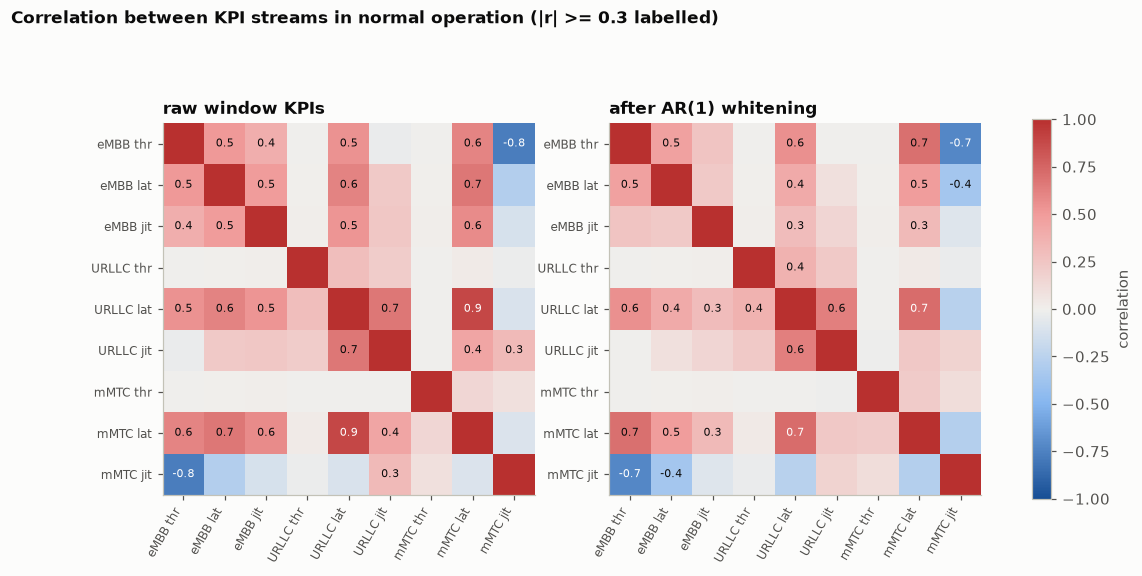

,pair,raw,whitened
0,eMBB lat / URLLC lat,0.62,0.41
1,eMBB lat / mMTC lat,0.67,0.49
2,URLLC lat / mMTC lat,0.89,0.72
3,eMBB thr / URLLC thr,-0.01,-0.01
4,eMBB thr / mMTC thr,-0.00,-0.00
5,eMBB lat / eMBB thr,0.51,0.46


In [5]:
STREAMS = [(s, k) for s in range(len(names)) for k in ("throughput_mbps", "latency_ms", "jitter_ms")]
LABELS = [f"{names[s]} {k.split('_')[0][:3]}" for s, k in STREAMS]

def stream_matrix(res, run):
    X = np.column_stack([res.kpi(k)[run, :, s] for s, k in STREAMS])
    return pd.DataFrame(X).ffill().bfill().to_numpy()       # fill the rare empty windows

def ar1_whiten(X):
    Xc = X - X.mean(axis=0)
    phi = (Xc[1:] * Xc[:-1]).sum(axis=0) / (Xc**2).sum(axis=0)
    return Xc[1:] - phi * Xc[:-1], phi

corr_raw = np.mean([np.corrcoef(stream_matrix(res, r).T) for r in range(N_RUNS)], axis=0)
corr_white = np.mean([np.corrcoef(ar1_whiten(stream_matrix(res, r))[0].T) for r in range(N_RUNS)], axis=0)

DIVERGING = LinearSegmentedColormap.from_list("div", ["#184f95", "#86b6ef", "#f0efec", "#f19c9b", "#b8302f"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, C, title in [(axes[0], corr_raw, "raw window KPIs"), (axes[1], corr_white, "after AR(1) whitening")]:
    im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(LABELS)), LABELS, fontsize=8)
    ax.grid(False)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if i != j and abs(C[i, j]) >= 0.3:
                ax.text(j, i, f"{C[i, j]:.1f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(C[i, j]) > 0.7 else INK)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation")
fig.suptitle("Correlation between KPI streams in normal operation (|r| >= 0.3 labelled)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
save_fig(fig, "fig2_correlation")
plt.show()

idx = {lab: i for i, lab in enumerate(LABELS)}
pairs = [("eMBB lat", "URLLC lat"), ("eMBB lat", "mMTC lat"), ("URLLC lat", "mMTC lat"),
         ("eMBB thr", "URLLC thr"), ("eMBB thr", "mMTC thr"), ("eMBB lat", "eMBB thr")]
coupling = pd.DataFrame([dict(pair=f"{a} / {b}", raw=corr_raw[idx[a], idx[b]], whitened=corr_white[idx[a], idx[b]])
                         for a, b in pairs])
coupling.round(2)

**What it shows**

- **Latency is strongly coupled across slices, and most of the coupling survives whitening.** The eMBB–URLLC latency correlation is 0.62 raw and 0.41 after whitening; URLLC–mMTC is 0.89 and 0.72. Two common causes push all latencies up together. eMBB bursts occupy the server, so the other slices run at their guaranteed rates instead of borrowing, and capacity dips slow everyone.
- **Throughput is not coupled** (|r| ≈ 0.01). Below their guaranteed shares, URLLC and mMTC deliver exactly what arrives, which does not depend on the other slices. At this load, coupling lives in the delay KPIs, not the rate KPIs.
- **The coupling is positive.** In notebook 02's terms, ρ ≈ 0.4–0.7 between latency residuals. Faults that raise every slice's latency together, such as a capacity drop, move along the normal coupling (shape near (1, 1) or (1, ρ)) and should gain little from a coupled detector. Faults confined to one slice, such as a URLLC traffic surge, break it and should gain about 1/(1 − ρ²) ≈ 1.2–2.1×. Measuring the actual fault signatures is task 5.
- **Caveat.** The strong negative correlation between eMBB throughput and mMTC jitter (−0.8) comes partly from the simulator's within-slot service assumption: when eMBB is saturated, mMTC is served at a steady rate and its delay varies less. It should not be read as a property of real networks.

## 6. Memory

Autocorrelation of each KPI stream up to 5 s (50 windows), averaged over the four runs. Notebook 01 found that AR(1) noise with $\phi = 0.7$ cut CUSUM's ARL about sixfold, so this decides how much whitening matters.

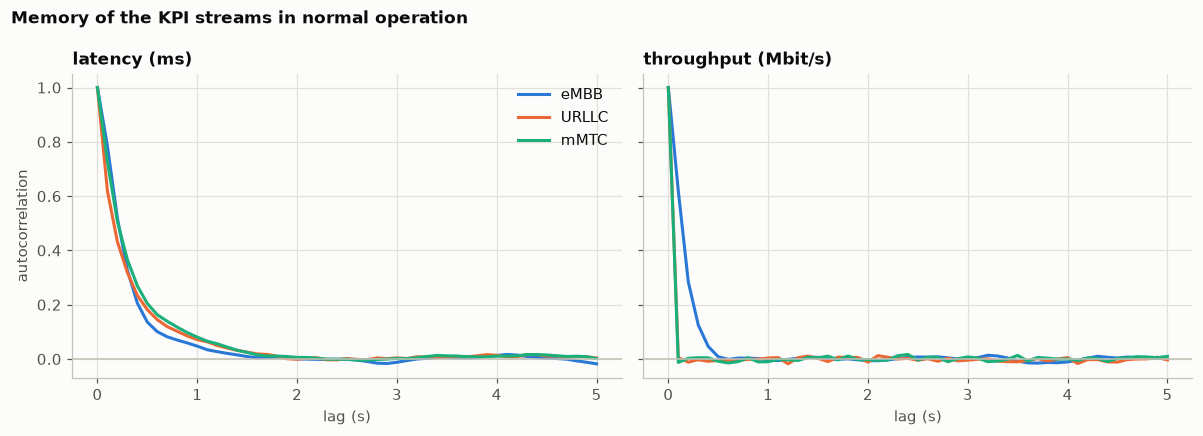

,stream,lag1,lag5,lag20,lag1_after_whitening
0,eMBB throughput_mbps,0.62,0.01,-0.01,0.10
1,eMBB latency_ms,0.78,0.14,0.00,0.20
2,eMBB jitter_ms,0.28,0.07,-0.01,-0.03
3,URLLC throughput_mbps,0.01,-0.01,-0.01,0.00
4,URLLC latency_ms,0.62,0.18,-0.00,-0.05
5,URLLC jitter_ms,0.32,0.15,0.01,-0.05
6,mMTC throughput_mbps,-0.01,-0.01,-0.00,0.00
7,mMTC latency_ms,0.73,0.20,0.01,0.04
8,mMTC jitter_ms,0.59,0.11,-0.01,-0.01


In [6]:
def acf(x, max_lag):
    x = x - x.mean()
    d = (x**2).sum()
    return np.array([1.0] + [(x[l:] * x[:-l]).sum() / d for l in range(1, max_lag + 1)])

MAX_LAG = 50
acfs = {}
for s, k in STREAMS:
    acfs[(s, k)] = np.mean([acf(pd.Series(res.kpi(k)[r, :, s]).ffill().bfill().to_numpy(), MAX_LAG)
                            for r in range(N_RUNS)], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
lags = np.arange(MAX_LAG + 1) * res.window_s
for ax, k in zip(axes, ["latency_ms", "throughput_mbps"]):
    for s, name in enumerate(names):
        a = acfs[(s, k)]
        ax.plot(lags, a, color=SLICE_COLORS[s], label=name)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_xlabel("lag (s)")
    ax.set_title(KPI_LABEL[k])
axes[0].set_ylabel("autocorrelation")
axes[0].legend()
fig.suptitle("Memory of the KPI streams in normal operation", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig3_acf")
plt.show()

memory = pd.DataFrame([dict(stream=f"{names[s]} {k}", lag1=acfs[(s, k)][1], lag5=acfs[(s, k)][5],
                            lag20=acfs[(s, k)][20]) for s, k in STREAMS])
memory["lag1_after_whitening"] = np.mean([[acf(col, 1)[1] for col in ar1_whiten(stream_matrix(res, r))[0].T]
                                          for r in range(N_RUNS)], axis=0)
memory.round(2)

**What it shows**

- **Latency has strong short-term memory.** Lag-1 autocorrelation is 0.62–0.78 (one window = 100 ms), decaying to near zero by about 2 s. By notebook 01's AR(1) experiment, a CUSUM on raw latency with i.i.d. thresholds would raise false alarms several times too often.
- **Throughput memory follows the traffic model.** eMBB throughput has memory from its on-off bursts (lag-1 0.62). URLLC and mMTC throughput have none: their Poisson traffic is served immediately.
- **AR(1) whitening removes most of it.** After whitening, lag-1 autocorrelation is within ±0.05 for every stream except eMBB latency (0.20) and eMBB throughput (0.10). Their burst structure needs a richer model, such as a higher-order AR or a model that tracks the on-off state.

## 7. Shape

Detectors built on Gaussian likelihoods assume symmetric, light-tailed noise. The latency distributions below say how far off that is.

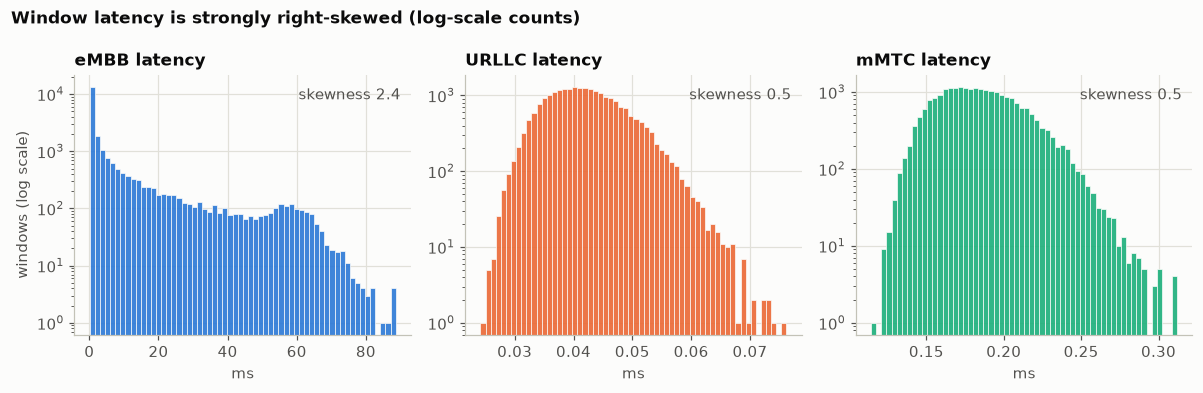

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for s, (ax, name) in enumerate(zip(axes, names)):
    v = res.kpi("latency_ms")[..., s].ravel()
    v = v[~np.isnan(v)]
    ax.hist(v, bins=60, color=SLICE_COLORS[s], alpha=0.9, edgecolor=SURFACE, linewidth=0.5)
    ax.set_yscale("log")
    ax.set_title(f"{name} latency")
    ax.set_xlabel("ms")
    ax.annotate(f"skewness {stats.skew(v):.1f}", (0.97, 0.95), xycoords="axes fraction", ha="right", va="top", color=INK2)
axes[0].set_ylabel("windows (log scale)")
fig.suptitle("Window latency is strongly right-skewed (log-scale counts)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig4_latency_hist")
plt.show()

## 8. Higher load

The same scenario with the server's capacity cut from 100 to 80 Mbit/s (offered load 56% → 70% of nominal capacity). How do memory and coupling change?

In [8]:
cfg_hi = copy.deepcopy(cfg)
cfg_hi.capacity.mbps = 80.0
res_hi = simulate(cfg_hi, n_windows=3000, n_runs=N_RUNS, seed=SEED + 1)

def scenario_row(label, r, c):
    lat = r.kpi("latency_ms")
    X = [stream_matrix(r, i) for i in range(r.kpis.shape[0])]
    cr = np.mean([np.corrcoef(x.T) for x in X], axis=0)
    cw = np.mean([np.corrcoef(ar1_whiten(x)[0].T) for x in X], axis=0)
    a = lambda s, k: np.mean([acf(pd.Series(r.kpi(k)[i, :, s]).ffill().bfill().to_numpy(), 1)[1]
                              for i in range(r.kpis.shape[0])])
    i, j = idx["eMBB lat"], idx["URLLC lat"]
    return dict(scenario=label, load=c.offered_load(),
                eMBB_latency_mean=np.nanmean(lat[..., 0]), eMBB_latency_p99=np.nanpercentile(lat[..., 0], 99),
                eMBB_loss_pct=np.nanmean(r.kpi("loss_pct")[..., 0]),
                URLLC_latency_mean=np.nanmean(lat[..., 1]),
                eMBB_lat_lag1=a(0, "latency_ms"), URLLC_lat_lag1=a(1, "latency_ms"),
                corr_eMBB_URLLC_lat_raw=cr[i, j], corr_eMBB_URLLC_lat_white=cw[i, j])

scen = pd.DataFrame([scenario_row("default (100 Mbit/s)", res, cfg), scenario_row("high load (80 Mbit/s)", res_hi, cfg_hi)])
scen.round(3).T

,0,1
scenario,default (100 Mbit/s),high load (80 Mbit/s)
load,0.556,0.695
eMBB_latency_mean,8.314,19.935
eMBB_latency_p99,64.368,70.947
eMBB_loss_pct,0.768,6.403
URLLC_latency_mean,0.042,0.053
eMBB_lat_lag1,0.784,0.703
URLLC_lat_lag1,0.619,0.632
corr_eMBB_URLLC_lat_raw,0.615,0.655
corr_eMBB_URLLC_lat_white,0.411,0.501


**What it shows**

- **Slicing still protects URLLC at higher load.** At 80 Mbit/s (load 70%), eMBB's mean latency more than doubles (8.3 → 19.9 ms) and its loss rises from 0.8% to 6.4%, while URLLC latency rises only from 42 to 53 µs.
- **Coupling gets stronger with load.** The whitened eMBB–URLLC latency correlation rises from 0.41 to 0.50. Memory changes little.
- **The operating point matters.** The size of the coupling, and so the value of a coupled detector, depends on it, so the evaluation should report results at more than one load.

In [9]:
# Export tables and key numbers for report/main.tex
def fmt(v, nd=2):
    return f"{v:.{nd}f}"

tab = summary[summary.kpi != "jitter_ms"].assign(
    kpi=summary.kpi.map({"throughput_mbps": "throughput (Mbit/s)", "latency_ms": "latency (ms)",
                         "loss_pct": "loss (\\%)"}),
    mean=summary["mean"].map(lambda v: f"{v:.3g}"), sd=summary["sd"].map(lambda v: f"{v:.3g}"),
    p99=summary["p99"].map(lambda v: f"{v:.3g}"), skewness=summary["skewness"].map("{:.1f}".format),
)[["slice", "kpi", "mean", "sd", "p99", "skewness"]]
save_tex_table(tab, "kpi_summary", "llrrrr")

tab = coupling.assign(pair=coupling.pair, raw=coupling.raw.map(fmt), whitened=coupling.whitened.map(fmt))
tab.columns = ["pair", "raw", "after whitening"]
save_tex_table(tab, "coupling", "lrr")

tab = memory.assign(**{c: memory[c].map(fmt) for c in ["lag1", "lag5", "lag20", "lag1_after_whitening"]})
tab["stream"] = tab["stream"].str.replace("_", r"\_", regex=False)
tab.columns = ["stream", "lag 1", "lag 5", "lag 20", "lag 1, whitened"]
save_tex_table(tab, "memory", "lrrrr")

S = summary.set_index(["slice", "kpi"])
C = coupling.set_index("pair")
M = memory.set_index("stream")
H = scen.set_index("scenario")
save_tex_numbers({
    "SimLoad": f"{100 * cfg.offered_load():.0f}",
    "SimEmbbLatMean": f"{S.loc[('eMBB', 'latency_ms'), 'mean']:.1f}",
    "SimEmbbLatPNN": f"{S.loc[('eMBB', 'latency_ms'), 'p99']:.0f}",
    "SimEmbbLoss": f"{S.loc[('eMBB', 'loss_pct'), 'mean']:.2f}",
    "SimUrllcLatMean": f"{1000 * S.loc[('URLLC', 'latency_ms'), 'mean']:.0f}",
    "SimEmbbLatSkew": f"{S.loc[('eMBB', 'latency_ms'), 'skewness']:.1f}",
    "SimCorrEULatRaw": fmt(C.loc["eMBB lat / URLLC lat", "raw"]),
    "SimCorrEULatWhite": fmt(C.loc["eMBB lat / URLLC lat", "whitened"]),
    "SimCorrUMLatRaw": fmt(C.loc["URLLC lat / mMTC lat", "raw"]),
    "SimCorrUMLatWhite": fmt(C.loc["URLLC lat / mMTC lat", "whitened"]),
    "SimEmbbLatLagOne": fmt(M.loc["eMBB latency_ms", "lag1"]),
    "SimUrllcLatLagOne": fmt(M.loc["URLLC latency_ms", "lag1"]),
    "SimEmbbLatLagOneWhite": fmt(M.loc["eMBB latency_ms", "lag1_after_whitening"]),
    "SimHiEmbbLatMean": f"{H.loc['high load (80 Mbit/s)', 'eMBB_latency_mean']:.1f}",
    "SimHiEmbbLoss": f"{H.loc['high load (80 Mbit/s)', 'eMBB_loss_pct']:.1f}",
    "SimHiCorrEULatWhite": fmt(H.loc['high load (80 Mbit/s)', 'corr_eMBB_URLLC_lat_white']),
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("03_*")))

exported: ['03_coupling.tex', '03_kpi_summary.tex', '03_memory.tex', '03_numbers.tex', '03_slices.tex']


## 9. Summary

- **The simulator reproduces what slicing is meant to do.** eMBB bursts borrow idle capacity and queue, while URLLC and mMTC, below their guaranteed shares, stay fast and lossless.
- **Coupling exists, and it is in latency.** Whitened cross-slice latency correlations are 0.4–0.7 and grow with load. Throughput is uncorrelated across slices at this load.
- **KPIs have memory and are not Gaussian.** Latency lag-1 autocorrelation is 0.6–0.8; eMBB latency is bimodal and skewed; URLLC loss is almost always zero. Detectors must work on whitened residuals, and thresholds must be calibrated by simulation, not by Gaussian formulas.
- **Next (task 5).** Inject faults (capacity drop, traffic surge in one slice, loss burst, slow degradation), measure each fault's signature δ in whitened-residual space, and see which faults break the normal coupling.